<a href="https://colab.research.google.com/github/jessienatash4/SMT5_Data-Communication/blob/main/Program_Week_6_PQRST_DWT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Deteksi Gelombang PQRST pada Sinyal ECG menggunakan metode Discrete Wavelet Transform (DWT) dengan Wavelet Bebas**
Jessie Natasha
NRP. 5049241015

---



## **1. Instalasi library**

In [1]:
!pip -q install PyWavelets scipy pandas matplotlib numpy

## **2. Upload dan baca dataset**

In [2]:
from google.colab import files
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt

from scipy.signal import butter, sosfiltfilt, find_peaks

uploaded = files.upload()

filename = "ptbdb_normal.csv"
df = pd.read_csv(io.BytesIO(uploaded[filename]), header=None)

print("Ukuran dataset:", df.shape)
display(df.head())
print("\nJumlah nilai kosong:", df.isna().sum().sum())

Saving ptbdb_normal.csv to ptbdb_normal.csv
Ukuran dataset: (4046, 188)


,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,1.000000,0.900324,0.358590,0.051459,0.046596,0.126823,0.133306,0.119125,0.110616,0.113047,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.000000,0.794681,0.375387,0.116883,0.000000,0.171923,0.283859,0.293754,0.325912,0.345083,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.909029,0.791482,0.423169,0.186712,0.000000,0.007836,0.063032,0.077002,0.074957,0.077342,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.000000,0.478893,0.056760,0.064176,0.081289,0.072732,0.055619,0.048774,0.054478,0.041643,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.000000,0.867238,0.201360,0.099349,0.141336,0.120934,0.108516,0.096393,0.093436,0.100828,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Jumlah nilai kosong: 0


## **3. Identifikasi dan pilih sinyal ECG**

In [3]:
FS = 125  # Sampling frequency dalam Hz
WAVELET = "db4"
LEVEL = 5

# Konversi kolom menjadi numerik jika memungkinkan
data = df.apply(pd.to_numeric, errors="coerce")

# Hapus kolom yang sepenuhnya kosong
data = data.dropna(axis=1, how="all")

# Hapus baris yang mengandung nilai kosong
data = data.dropna(axis=0, how="any").reset_index(drop=True)

# Deteksi kolom label biner pada kolom terakhir
last_col = data.iloc[:, -1].to_numpy()
is_binary_label = (
    len(np.unique(last_col)) <= 2
    and set(np.unique(last_col)).issubset({0, 1})
    and data.shape[1] > 2
)

if is_binary_label:
    signal_data = data.iloc[:, :-1].to_numpy(dtype=float)
    labels = data.iloc[:, -1].to_numpy()
    print("Kolom terakhir terdeteksi sebagai label.")
else:
    signal_data = data.to_numpy(dtype=float)
    labels = None
    print("Tidak terdeteksi kolom label biner.")

print("Jumlah segmen ECG:", signal_data.shape[0])
print("Jumlah titik per segmen:", signal_data.shape[1])

# Pilih satu segmen ECG untuk analisis
SEGMENT_INDEX = 0
ecg_raw = signal_data[SEGMENT_INDEX].astype(float)

if labels is not None:
    print("Label segmen terpilih:", labels[SEGMENT_INDEX])

time = np.arange(len(ecg_raw)) / FS
print(f"Durasi segmen: {len(ecg_raw)/FS:.3f} detik")

Kolom terakhir terdeteksi sebagai label.
Jumlah segmen ECG: 4046
Jumlah titik per segmen: 187
Label segmen terpilih: 0.0
Durasi segmen: 1.496 detik


## **4. Visualisasi sinyal ECG asli**

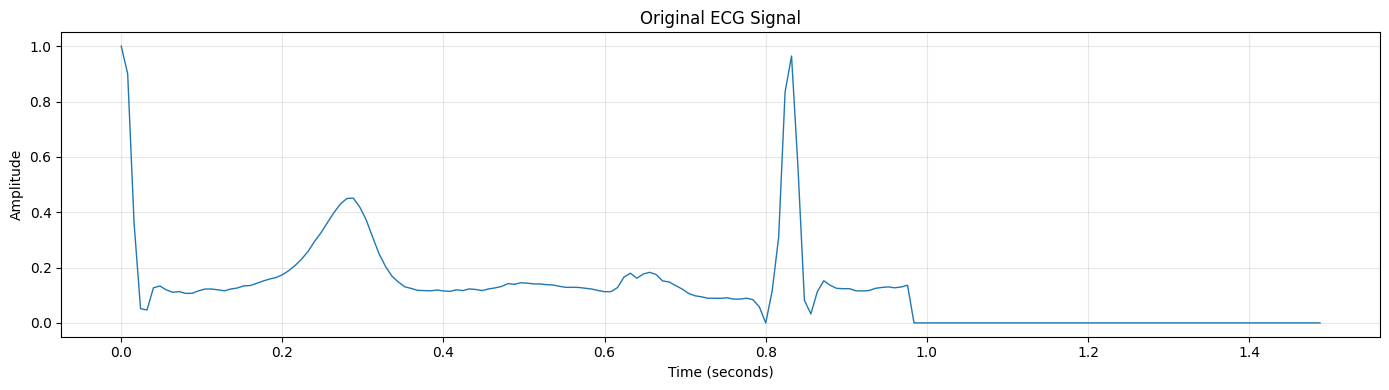

In [4]:
plt.figure(figsize=(14, 4))
plt.plot(time, ecg_raw, linewidth=1)
plt.title("Original ECG Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## **5. Preprocessing ECG**

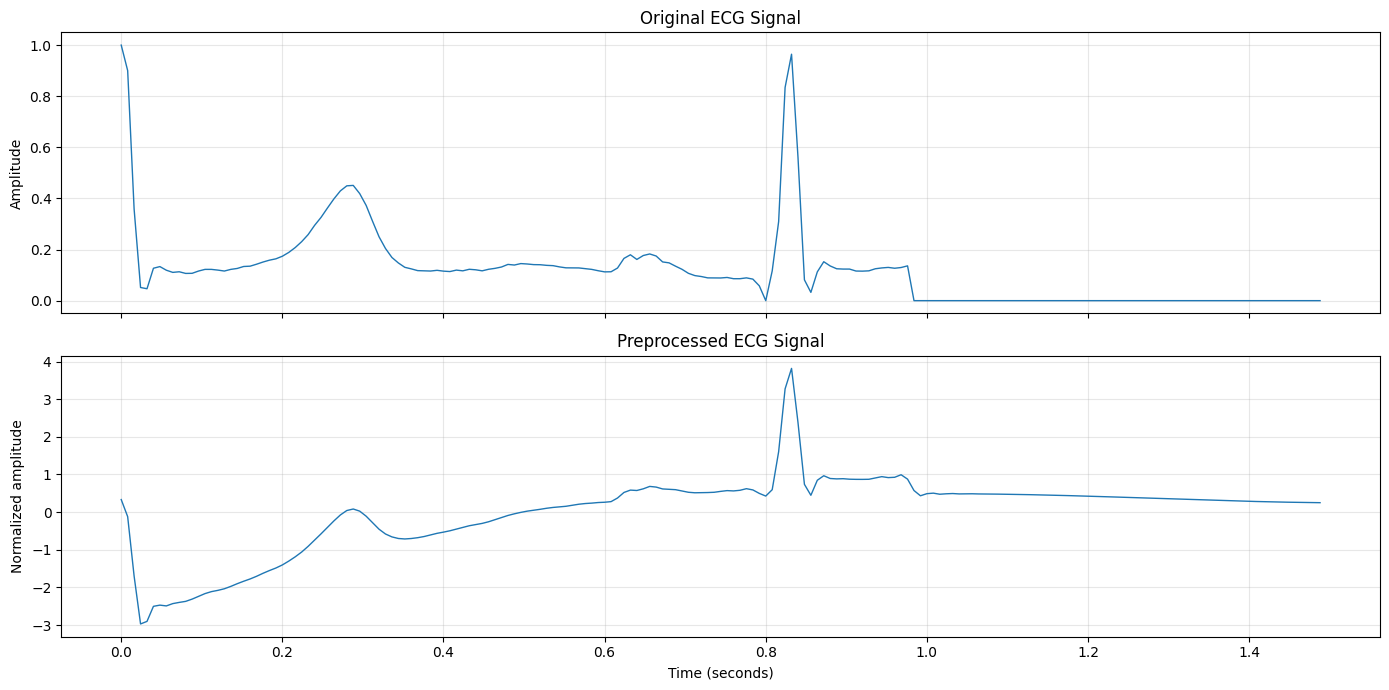

In [5]:
# Bandpass filter
lowcut = 0.5
highcut = 40.0

sos = butter(
    N=4,
    Wn=[lowcut, highcut],
    btype="bandpass",
    fs=FS,
    output="sos"
)

# Untuk menghindari error pada sinyal terlalu pendek
if len(ecg_raw) <= 3 * (2 * len(sos) + 1):
    raise ValueError(
        "Segmen terlalu pendek untuk filtering. "
        "Periksa jumlah titik pada segmen yang dipilih."
    )

ecg_filtered = sosfiltfilt(sos, ecg_raw)

# Normalisasi z-score
std_val = np.std(ecg_filtered)
if std_val == 0:
    raise ValueError("Sinyal konstan; preprocessing tidak dapat dilanjutkan.")

ecg_processed = (
    ecg_filtered - np.mean(ecg_filtered)
) / std_val

# Perbandingan sinyal
fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

ax[0].plot(time, ecg_raw, linewidth=1)
ax[0].set_title("Original ECG Signal")
ax[0].set_ylabel("Amplitude")
ax[0].grid(True, alpha=0.3)

ax[1].plot(time, ecg_processed, linewidth=1)
ax[1].set_title("Preprocessed ECG Signal")
ax[1].set_xlabel("Time (seconds)")
ax[1].set_ylabel("Normalized amplitude")
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## **6. Visualisasi koefisien filter DWT *h[n]* dan *g[n]***

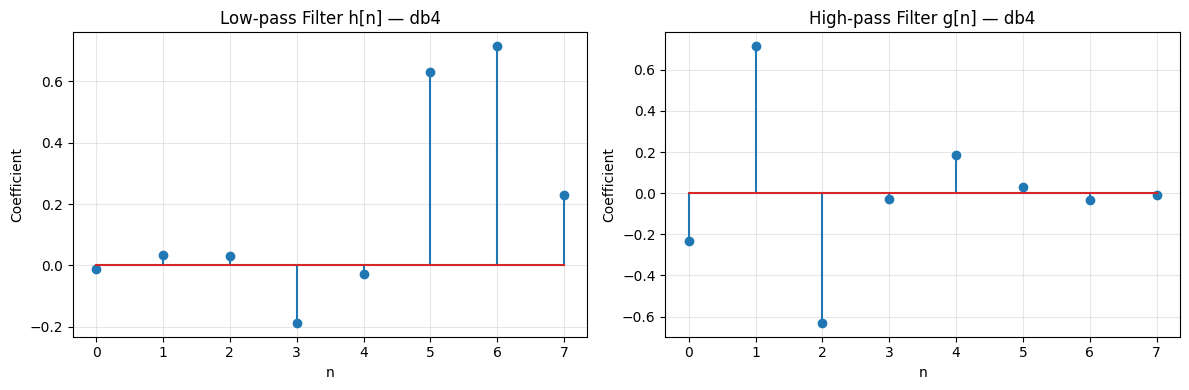

In [6]:
wave = pywt.Wavelet(WAVELET)

h = np.array(wave.dec_lo)  # Low-pass decomposition filter
g = np.array(wave.dec_hi)  # High-pass decomposition filter

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].stem(np.arange(len(h)), h)
ax[0].set_title(f"Low-pass Filter h[n] — {WAVELET}")
ax[0].set_xlabel("n")
ax[0].set_ylabel("Coefficient")
ax[0].grid(True, alpha=0.3)

ax[1].stem(np.arange(len(g)), g)
ax[1].set_title(f"High-pass Filter g[n] — {WAVELET}")
ax[1].set_xlabel("n")
ax[1].set_ylabel("Coefficient")
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## **7. Visualisasi scaling function dan wavelet function**

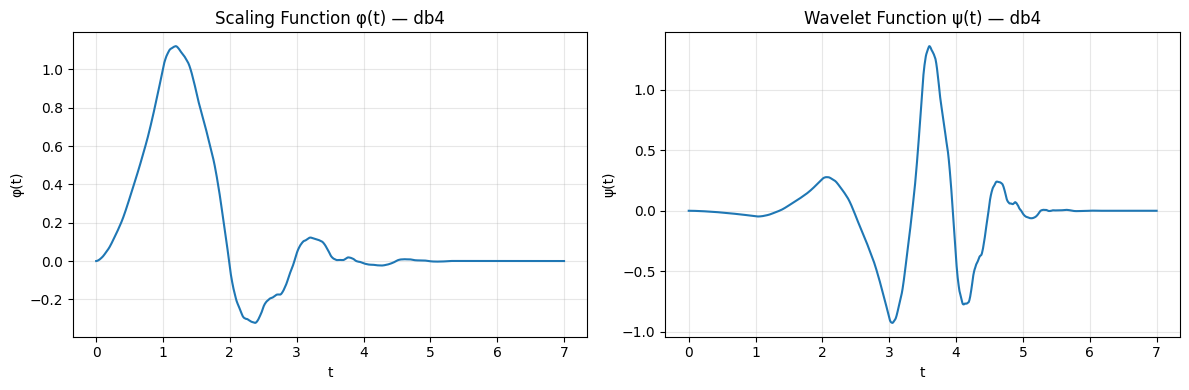

In [7]:
phi, psi, x_wave = wave.wavefun(level=8)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(x_wave, phi)
ax[0].set_title(f"Scaling Function φ(t) — {WAVELET}")
ax[0].set_xlabel("t")
ax[0].set_ylabel("φ(t)")
ax[0].grid(True, alpha=0.3)

ax[1].plot(x_wave, psi)
ax[1].set_title(f"Wavelet Function ψ(t) — {WAVELET}")
ax[1].set_xlabel("t")
ax[1].set_ylabel("ψ(t)")
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## **8. Dekomposisi DWT pada setiap level**

/usr/local/lib/python3.13/dist-packages/pywt/_multilevel.py:43: UserWarning: Level value of 5 is too high: all coefficients will experience boundary effects.
  warnings.warn(


Wavelet: db4
Level dekomposisi: 5
Panjang A5: 12
Panjang D5: 12
Panjang D4: 18
Panjang D3: 29
Panjang D2: 52
Panjang D1: 97


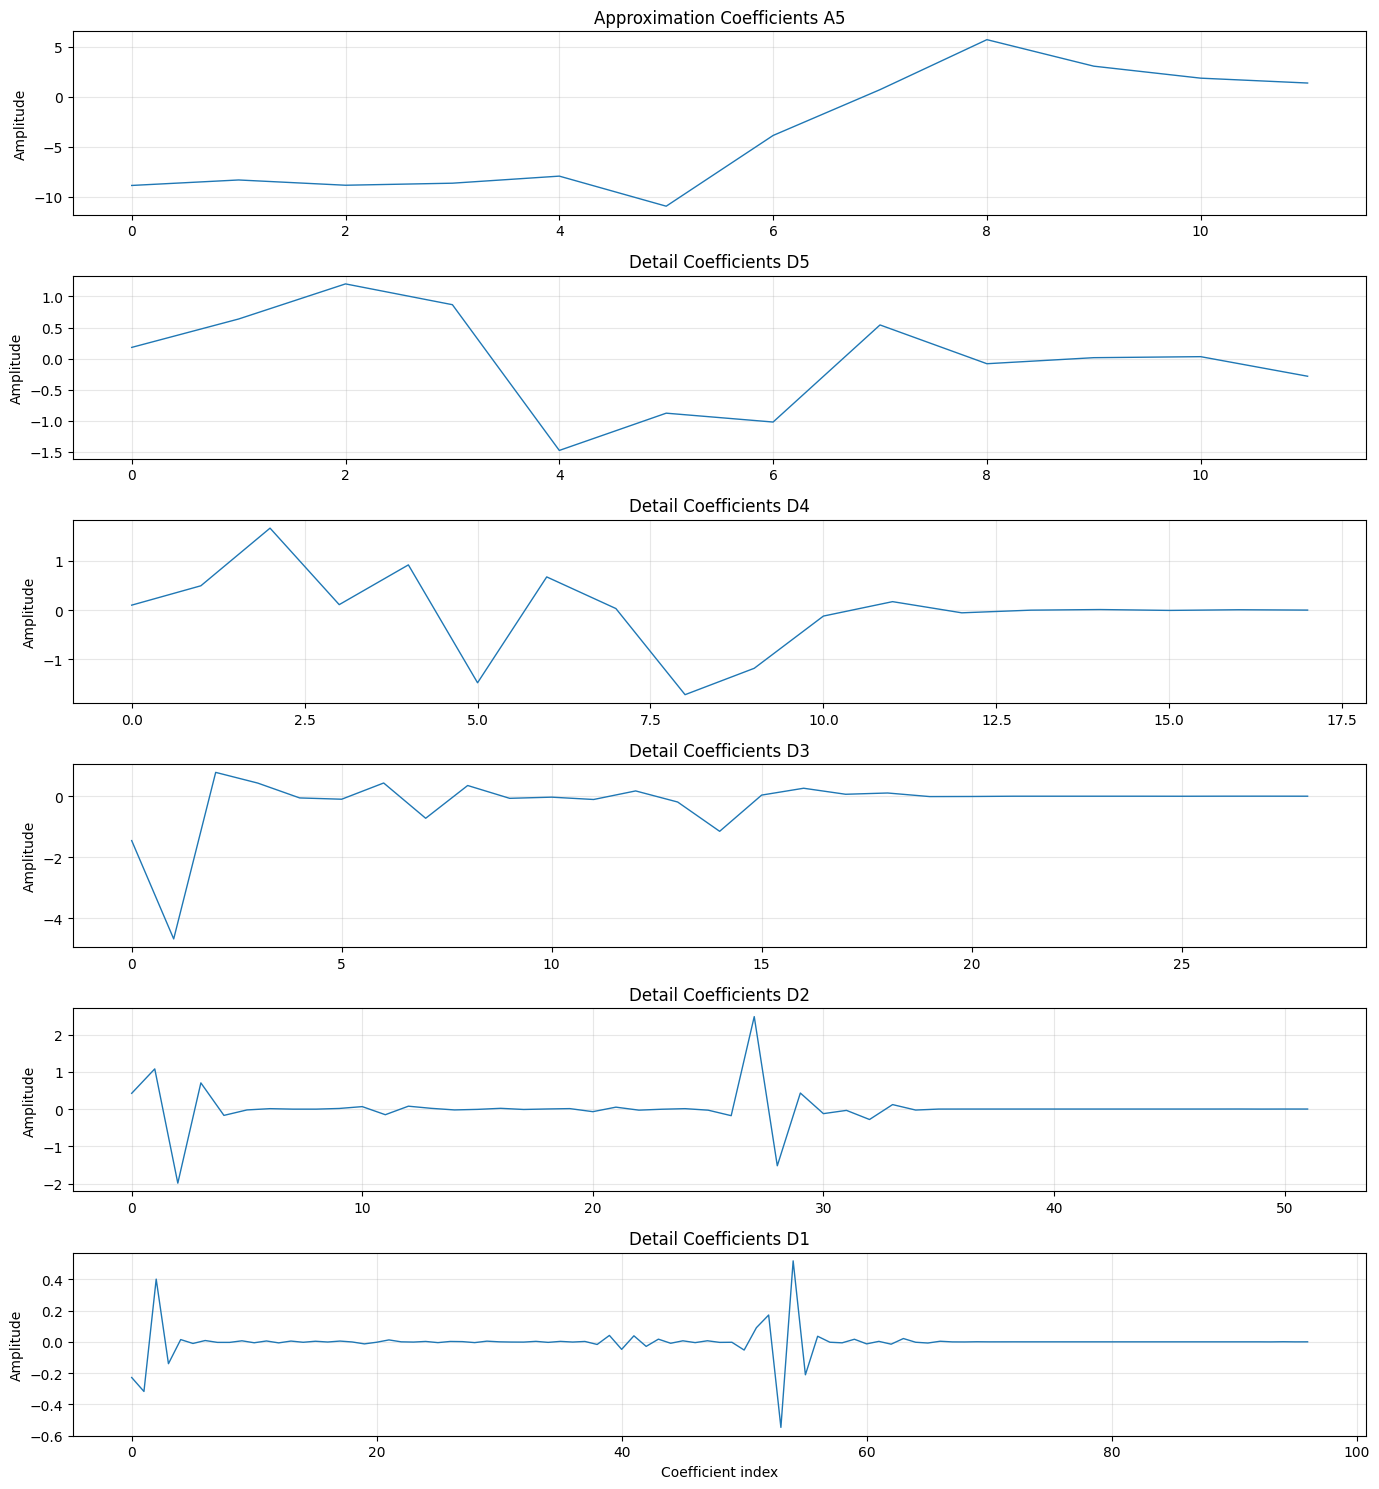

In [8]:
coeffs = pywt.wavedec(
    ecg_processed,
    wavelet=WAVELET,
    level=LEVEL,
    mode="symmetric"
)

# Format wavedec: [A5, D5, D4, D3, D2, D1]
approx_coeff = coeffs[0]
detail_coeffs = coeffs[1:]

print("Wavelet:", WAVELET)
print("Level dekomposisi:", LEVEL)
print("Panjang A5:", len(approx_coeff))

for i, d in enumerate(detail_coeffs):
    level = LEVEL - i
    print(f"Panjang D{level}: {len(d)}")

fig, ax = plt.subplots(LEVEL + 1, 1, figsize=(14, 15))

ax[0].plot(approx_coeff, linewidth=1)
ax[0].set_title(f"Approximation Coefficients A{LEVEL}")
ax[0].set_ylabel("Amplitude")
ax[0].grid(True, alpha=0.3)

for i, d in enumerate(detail_coeffs):
    level = LEVEL - i
    ax[i + 1].plot(d, linewidth=1)
    ax[i + 1].set_title(f"Detail Coefficients D{level}")
    ax[i + 1].set_ylabel("Amplitude")
    ax[i + 1].grid(True, alpha=0.3)

ax[-1].set_xlabel("Coefficient index")
plt.tight_layout()
plt.show()

## **9. Rekonstruksi komponen DWT untuk analisis QRS**

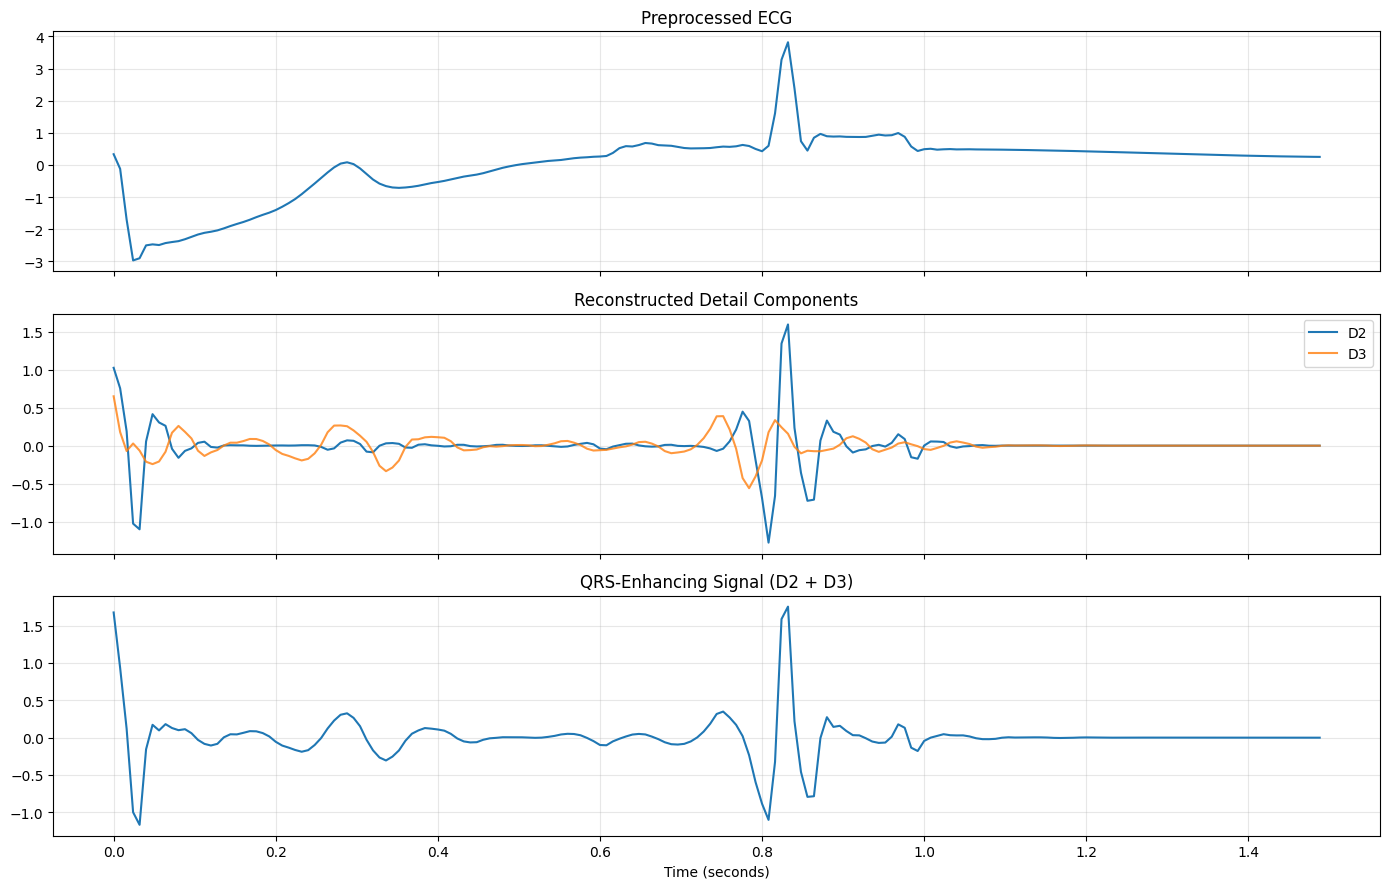

In [9]:
def reconstruct_component(coeffs, target_index, wavelet, signal_length):
    """
    Rekonstruksi satu komponen DWT.
    target_index: 0 untuk A5, 1 untuk D5, ..., 5 untuk D1.
    """
    selected = [
        np.zeros_like(c, dtype=float) for c in coeffs
    ]
    selected[target_index] = coeffs[target_index]

    reconstructed = pywt.waverec(
        selected, wavelet=wavelet, mode="symmetric"
    )
    return reconstructed[:signal_length]

# Urutan koefisien: [A5, D5, D4, D3, D2, D1]
A5_signal = reconstruct_component(coeffs, 0, WAVELET, len(ecg_processed))
D3_signal = reconstruct_component(coeffs, 3, WAVELET, len(ecg_processed))
D2_signal = reconstruct_component(coeffs, 4, WAVELET, len(ecg_processed))

qrs_signal = D2_signal + D3_signal

fig, ax = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

ax[0].plot(time, ecg_processed)
ax[0].set_title("Preprocessed ECG")
ax[0].grid(True, alpha=0.3)

ax[1].plot(time, D2_signal, label="D2")
ax[1].plot(time, D3_signal, label="D3", alpha=0.8)
ax[1].set_title("Reconstructed Detail Components")
ax[1].legend()
ax[1].grid(True, alpha=0.3)

ax[2].plot(time, qrs_signal)
ax[2].set_title("QRS-Enhancing Signal (D2 + D3)")
ax[2].set_xlabel("Time (seconds)")
ax[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## **10. Deteksi kandidat gelombang P, Q, R, S, dan T**

In [10]:
# 1. Deteksi kandidat R dari energi sinyal DWT
energy = qrs_signal ** 2

# Smoothing energi dengan moving average 40 ms
smooth_n = max(1, int(0.04 * FS))
energy_smooth = np.convolve(
    energy, np.ones(smooth_n) / smooth_n, mode="same"
)

# Jarak minimal antarkandidat R: 250 ms
min_distance = int(0.25 * FS)

# Threshold adaptif sederhana
height_threshold = np.mean(energy_smooth) + 0.5 * np.std(energy_smooth)

r_candidates, _ = find_peaks(
    energy_smooth,
    distance=min_distance,
    height=height_threshold
)

# Refinement: cari puncak positif ECG di sekitar kandidat
r_peaks = []
search_radius = int(0.08 * FS)

for candidate in r_candidates:
    left = max(0, candidate - search_radius)
    right = min(len(ecg_processed), candidate + search_radius + 1)

    if right <= left:
        continue

    local_peak = left + np.argmax(ecg_processed[left:right])
    r_peaks.append(local_peak)

# Hapus kandidat R yang terlalu berdekatan
r_peaks = sorted(set(r_peaks))
filtered_r = []

for r in r_peaks:
    if not filtered_r or r - filtered_r[-1] >= min_distance:
        filtered_r.append(r)
    elif ecg_processed[r] > ecg_processed[filtered_r[-1]]:
        filtered_r[-1] = r

r_peaks = np.array(filtered_r, dtype=int)

# 2. Estimasi Q, S, P, T berdasarkan jendela waktu di sekitar R
detections = []

for r in r_peaks:
    # Q: minimum sebelum R, sekitar 80 ms
    q_left = max(0, r - int(0.08 * FS))
    q_right = r

    # S: minimum setelah R, sekitar 100 ms
    s_left = r + 1
    s_right = min(len(ecg_processed), r + int(0.10 * FS) + 1)

    if q_right <= q_left or s_right <= s_left:
        continue

    q = q_left + np.argmin(ecg_processed[q_left:q_right])
    s = s_left + np.argmin(ecg_processed[s_left:s_right])

    # P: maksimum sebelum Q, dengan jendela 200–80 ms sebelum R
    p_left = max(0, r - int(0.20 * FS))
    p_right = max(p_left + 1, r - int(0.08 * FS))
    p_right = min(p_right, len(ecg_processed))

    # T: maksimum setelah S, dengan jendela 100–360 ms setelah R
    t_left = min(len(ecg_processed) - 1, r + int(0.10 * FS))
    t_right = min(len(ecg_processed), r + int(0.36 * FS))

    if p_right > p_left:
        p = p_left + np.argmax(ecg_processed[p_left:p_right])
    else:
        p = None

    if t_right > t_left:
        t = t_left + np.argmax(ecg_processed[t_left:t_right])
    else:
        t = None

    detections.append({
        "P": p,
        "Q": int(q),
        "R": int(r),
        "S": int(s),
        "T": t
    })

print("Jumlah kompleks yang terdeteksi:", len(detections))
for i, beat in enumerate(detections, start=1):
    print(f"Beat {i}: {beat}")

Jumlah kompleks yang terdeteksi: 1
Beat 1: {'P': np.int64(82), 'Q': 100, 'R': 104, 'S': 107, 'T': np.int64(121)}


## **11. Visualisasi ECG dengan penanda PQRST**

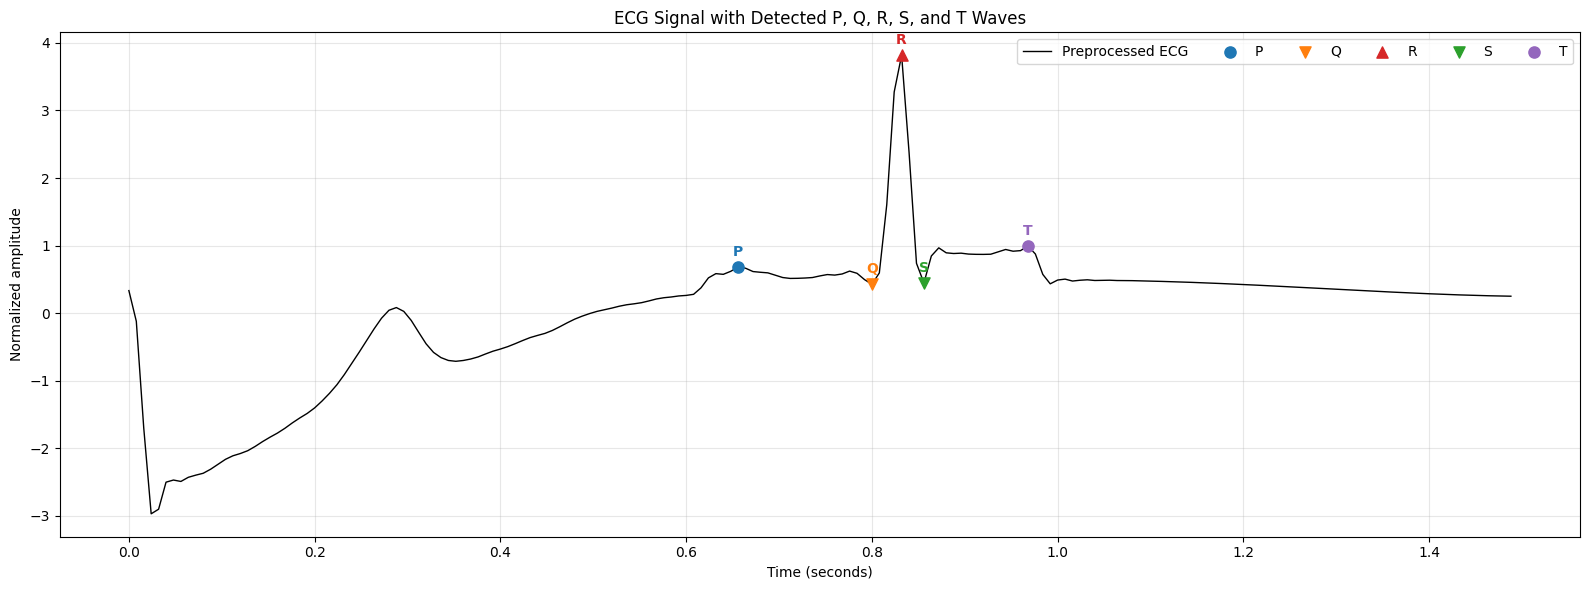

In [11]:
plt.figure(figsize=(16, 6))

plt.plot(
    time, ecg_processed,
    color="black", linewidth=1,
    label="Preprocessed ECG"
)

marker_style = {
    "P": ("o", "tab:blue"),
    "Q": ("v", "tab:orange"),
    "R": ("^", "tab:red"),
    "S": ("v", "tab:green"),
    "T": ("o", "tab:purple")
}

for beat in detections:
    for wave_name, index in beat.items():
        if index is not None and 0 <= index < len(ecg_processed):
            marker, color = marker_style[wave_name]
            plt.scatter(
                time[index],
                ecg_processed[index],
                marker=marker,
                color=color,
                s=65,
                zorder=3,
                label=wave_name
            )
            plt.annotate(
                wave_name,
                (time[index], ecg_processed[index]),
                xytext=(0, 8),
                textcoords="offset points",
                ha="center",
                color=color,
                fontsize=10,
                fontweight="bold"
            )

# Hilangkan duplikasi label legenda
handles, labels_legend = plt.gca().get_legend_handles_labels()
unique = dict(zip(labels_legend, handles))
plt.legend(unique.values(), unique.keys(), ncol=6)

plt.title("ECG Signal with Detected P, Q, R, S, and T Waves")
plt.xlabel("Time (seconds)")
plt.ylabel("Normalized amplitude")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## **12. Tabel hasil deteksi dan ekspor CSV**

In [12]:
rows = []

for beat_number, beat in enumerate(detections, start=1):
    row = {"Beat": beat_number}

    for wave_name, index in beat.items():
        row[f"{wave_name}_index"] = index
        row[f"{wave_name}_time_s"] = (
            index / FS if index is not None else np.nan
        )
        row[f"{wave_name}_amplitude"] = (
            ecg_processed[index]
            if index is not None else np.nan
        )

    rows.append(row)

results_df = pd.DataFrame(rows)
display(results_df)

results_df.to_csv("pqrst_detection_results.csv", index=False)
files.download("pqrst_detection_results.csv")

,Beat,P_index,P_time_s,P_amplitude,Q_index,Q_time_s,Q_amplitude,R_index,R_time_s,R_amplitude,S_index,S_time_s,S_amplitude,T_index,T_time_s,T_amplitude
0,1,82,0.656,0.682474,100,0.8,0.426189,104,0.832,3.817752,107,0.856,0.446384,121,0.968,0.992436


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>